## Data Preparation

In [1]:
import torch
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.autonotebook import tqdm

from hgctsvg.metadata import ProjectMetadata
from hgctsvg.preprocessing import common, singlecell, kidneycancer
from hgctsvg.utils import load_ct_spatial_data

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFou

Identify source and results directories

In [2]:
results_dir = Path("hgctsvg_project_files")
project_name = "Human Kidney Cancer Interface"

project_files_dir = results_dir / project_name
project_files_dir.mkdir(parents=True, exist_ok=True)

In [3]:
spotiphy_proj_dir = Path("spotiphy_project_files") / project_name

Load deconvolution results and spatial transcriptomics data.

Spatial transcriptomics data contains spot ids and spot locations, which are requirements for creating hyperedges.

In [4]:
adata_decomp = sc.read_h5ad(spotiphy_proj_dir / "ST_decomposition.h5ad")
adata_st = sc.read_h5ad(spotiphy_proj_dir / "Human Kidney Cancer Interface.h5ad")

The generated cell decomposition data does not yet include the cell locations generated by Spotiphy.
For visualization using Squidpy, we update adata with the generated locations.

In [5]:
adata_decomp = common.add_generated_cell_locations(spotiphy_proj_dir, adata_decomp, adata_st)

Prepared hires segmentation: (1834, 2000), 22430 cells


In [6]:
common_genes = set(adata_st.var_names).intersection(set(adata_decomp.var_names))
len(common_genes)

10827

### Make Project Metadata File

Generate a `ProjectMetadata` object. The `ProjectMetadata` file contains metadata about the project, which is used in several parts of the pipeline:
- `project_folder` - directory of the project.
- `ct_key` - cell type key used by adata objects to indicate the cell type of each cell.
- `ct_list` - list of cell types sorted in lexicographical order.
- `ct_mapping` - mapping of cell type names (`str`) to their positions in the `ct_list` (`int`). `ct_mapping` is important when preparing and accessing data in the pipeline.
- `n_cell_types` - number of cell types in the data.
- `dir_map` - mapping of directories to project subfolders

Creating `ProjectMetadata` requires `ct_key` as an argument, but once created, `ct_key` can also be accessed from the `ProjectMetadata`.

In [7]:
project_metadata = ProjectMetadata.create(project_files_dir, 
                             adata_decomp,
                             'cell_type')
# ct_metadata.ct_key, ct_metadata.ct_list, ct_metadata.ct_mapping, ct_metadata.n_cell_types

In [8]:
project_metadata.dir_map

{'attr_dir': 'attribution',
 'classifier_dir': 'classifiers',
 'clustering_dir': 'clustering',
 'ct_data_dir': 'ct_spatial_data',
 'plot_dir': 'plots'}

## Preprocessing

Preprocess original and decomposed ST data.

### General Preprocessing
Preprocess original ST data using standard preprocessing steps. Also perform HVG selection.

In [9]:
# Preprocessing and HVG detection
n_top_genes = 3000

# filter first before preprocess
adata_decomp = common.filter(adata_decomp, min_genes=20, min_locs=20)
adata_st = common.filter(adata_st, min_genes=20, min_locs=20)

# Preprocess ST data.
# Store unprocessed data to raw.
# Raw data is needed for visualization.
adata_st.raw = adata_st.copy()
sc.pp.highly_variable_genes(adata_st, flavor='seurat_v3', n_top_genes=n_top_genes)
sc.pp.normalize_total(adata_st, target_sum=1e6)
sc.pp.log1p(adata_st)

### Create separate anndata objects for each cell type.

For the decomposed data, we first separate them into different anndata objects per cell type using `preprocessing.singlecell.make_ct_spatial_data`, which also performs preprocessing on each anndata object separately. 

Then, get the top genes per cell type using `preprocessing.singlecell.perform_ct_feature_selection`.

In [10]:
n_features=3000
# singlecell.make_ct_spatial_adata(adata_decomp)
# singlecell.perform_ct_feature_selection(n_features=n_features)

Visualize distribution of each cell type within the tissue.

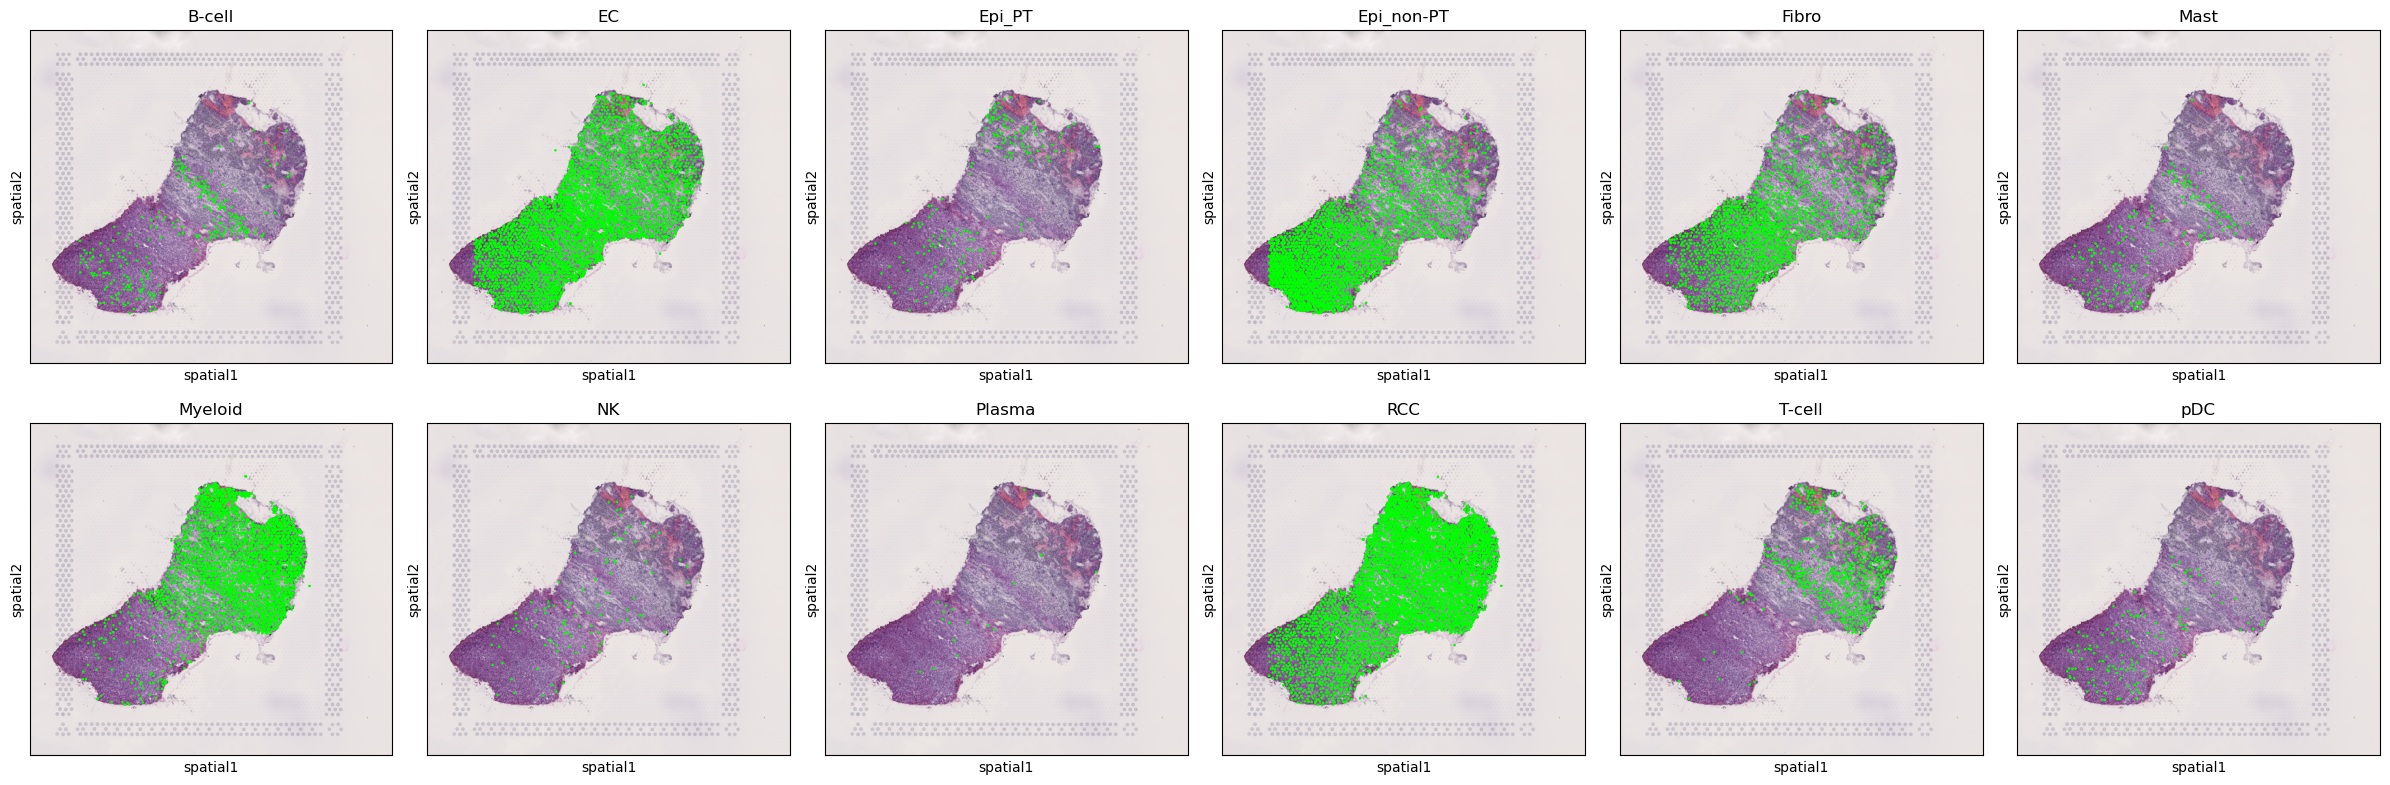

In [11]:
from hgctsvg.visualization import plot_all_ct_decomposition, plot_ct_decomposition
plot_all_ct_decomposition(n_cols=6)

# use this to plot each cell type separately
# plot_ct_decomposition(display=False, show_title=False)

Also visualize the distribution of genes on the original ST anndata object.

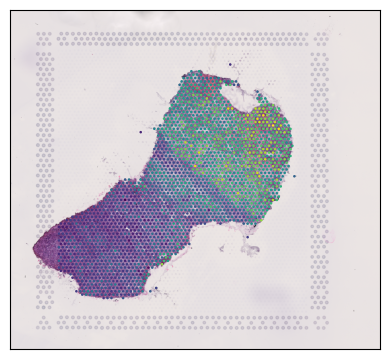

In [12]:
from hgctsvg.visualization import plot_st_gene_counts

plot_st_gene_counts(show_title=False, display=True)

## ML Dataset Creation

Create the Hypergraph Data for the ML pipeline.

In [13]:
hgdata = kidneycancer.create_hypergraph_data(adata_st, n_features=n_features, num_neighbor_spots=7)
hgdata.save()

Also save preprocessed ```adata_decomp``` and ```adata_st```

In [14]:
# save adata_st
adata_st.write_h5ad(project_files_dir / "ST_init.h5ad")

# save adata_decomp
adata_decomp.write_h5ad(project_files_dir / "ST_decomposition.h5ad")

# HGCTSVG Pipeline

For each step of the pipeline, run the following commands:

## I. Embedding Learning

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg train-embedder --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda
```

```bash
# Using CPU
hgctsvg train-embedder --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cpu
```

## II. Embedding Generation

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg make-embedding --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 100 --trainer.batch_size 22431 --trainer.accelerator cuda
```

```bash
# Using CPU
hgctsvg make-embedding --project "Human Kidney Cancer Interface" \
--model.model-name HyFiEmbedder --model.input-dim 3000 --model.embedding-dim 50 --model.dropout 0.2 \
--trainer.num_epochs 100 --trainer.batch_size 22431 --trainer.accelerator cpu
```

## III. Spatial Domain Identification

```bash
hgctsvg compute-spatial-domains --project "Human Kidney Cancer Interface" 
```

## IV. Cell-type Specific Domain Identification

```bash
hgctsvg compute-celltype-spatial-domains --project "Human Kidney Cancer Interface" \
--data.cell-type-key "cell_type"
```

## V. Classifier Training

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=1 hgctsvg train-celltype-domain-classifiers --project "Human Kidney Cancer Interface" \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cuda
```

```bash
# Using CPU
hgctsvg train-classifier --project "Human Kidney Cancer Interface" \
--classifier.embedding-dim 50 --classifier.num_layers 3 \
--trainer.num_epochs 1000 --trainer.batch_size 4096 --trainr.accelerator cpu
```

## VI. Spatial Gene Computation

```bash
# Using CUDA
CUDA_VISIBLE_DEVICES=0 hgctsvg compute-gene-to-celltype-domain-attribution --project "Human Kidney Cancer Interface" --cell-type RCC --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 100 --explainer.batch-size 8192 --explainer.accelerator cuda
```

```bash
# Using CPU
hgctsvg compute-gene-to-celltype-domain-attribution --project "Human Kidney Cancer Interface" --cell-type RCC --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 100 --explainer.batch-size 8192 --explainer.accelerator cpu
```


```bash
CUDA_VISIBLE_DEVICES=0 hgctsvg train-embedder --project "Human Kidney Cancer Interface" --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --model.dropout 0.2 --trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda
CUDA_VISIBLE_DEVICES=0 hgctsvg make-embedding --project "Human Kidney Cancer Interface" --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --model.dropout 0.2 --trainer.num_epochs 1000 --trainer.batch_size 22431 --trainer.accelerator cuda
# hgctsvg compute-spatial-domains --project "Human Kidney Cancer Interface"
hgctsvg compute-celltype-spatial-domains --project "Human Kidney Cancer Interface" --data.cell-type-key "cell_type"
CUDA_VISIBLE_DEVICES=0 hgctsvg train-celltype-domain-classifiers --project "Human Kidney Cancer Interface" --classifier.embedding-dim 200 --classifier.num_layers 3 --trainer.num_epochs 1000 --trainer.batch_size 4096 --trainer.accelerator cuda
CUDA_VISIBLE_DEVICES=0 hgctsvg compute-gene-to-celltype-domain-attribution --project "Human Kidney Cancer Interface" --cell-type RCC --model.model-name CTHGCAEEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 100 --explainer.batch-size 8192 --explainer.accelerator cuda

# CUDA_VISIBLE_DEVICES=0 hgctsvg compute-cell-embedding-attributions --project "Human Kidney Cancer Interface" --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 1000 --explainer.accelerator cuda
# CUDA_VISIBLE_DEVICES=0 hgctsvg compute-metagene-to-region-attribution --project "Human Kidney Cancer Interface" --cell-type EC --region 0 --classifier.embedding-dim 200 --classifier.num_layers 3 --explainer.n_steps 1000 --explainer.accelerator cuda
# CUDA_VISIBLE_DEVICES=0 hgctsvg compute-gene-to-cell-metagene-attribution --project "Human Kidney Cancer Interface" --model.model-name CTHyFiEmbedder --model.input-dim 3000 --model.embedding-dim 200 --model.latent-dim 500 --explainer.n_steps 100 --explainer.batch-size 8192 --explainer.accelerator cuda

```

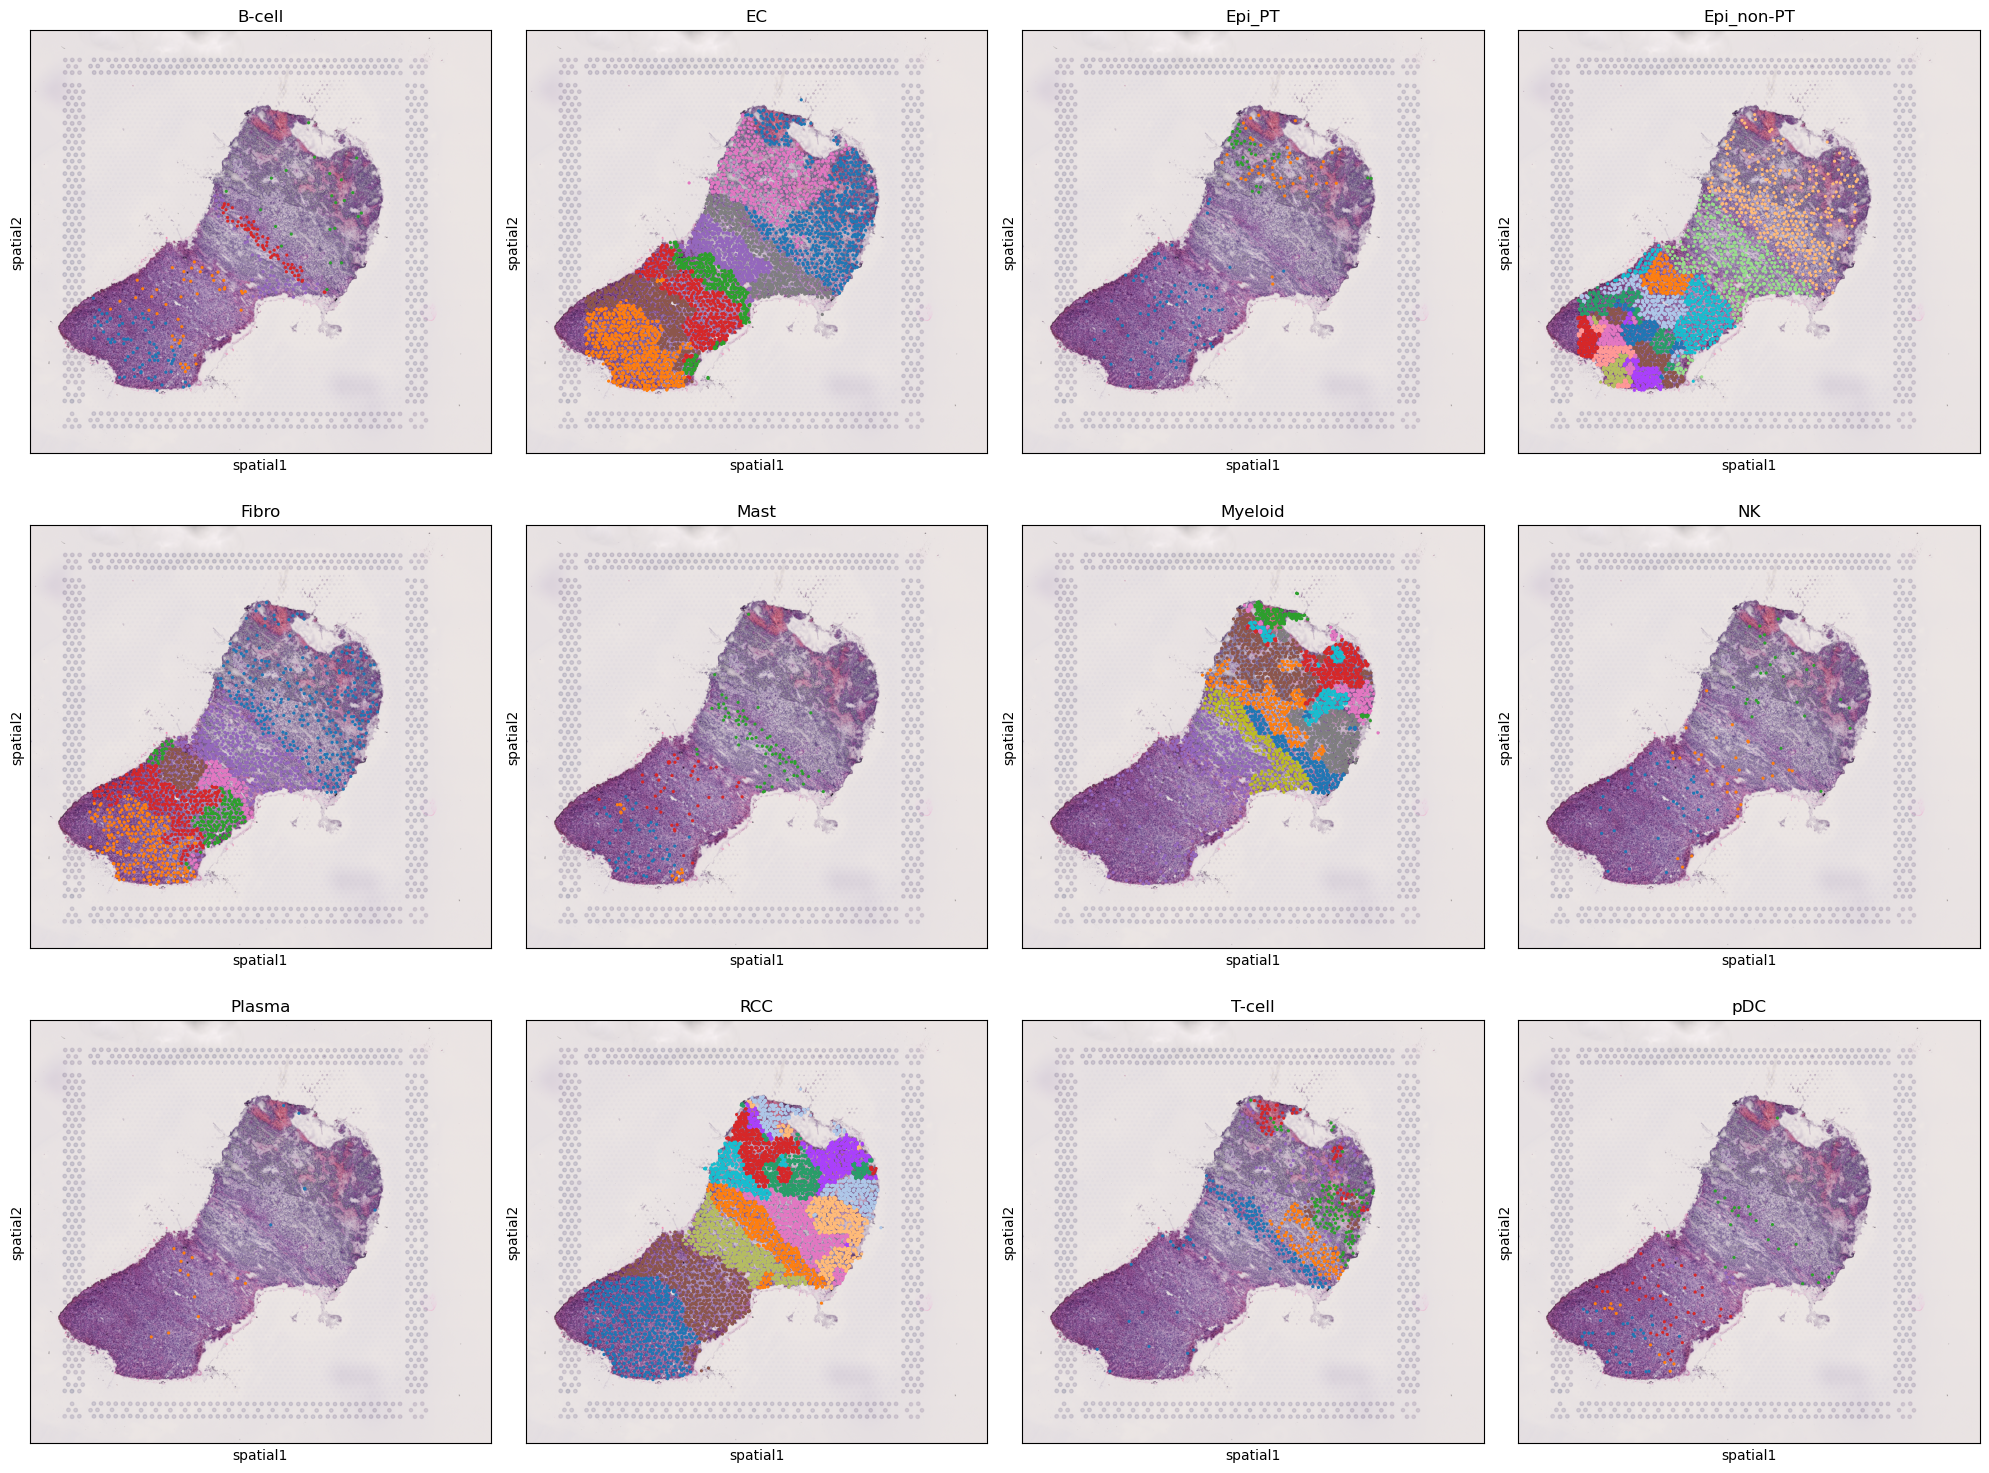

In [15]:
from hgctsvg.visualization import plot_all_ct_domains

plot_all_ct_domains()

In [16]:
adata_RCC = load_ct_spatial_data("RCC")
adata_RCC

AnnData object with n_obs × n_vars = 7176 × 10672
    obs: 'cell_type', 'spot_name', 'n_cell', 'location_x', 'location_y', 'library_id', 'segmentation', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'n_genes', 'leiden'
    var: 'SYMBOL', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'hvg_scores', 'spatial_scores', 'combined_scores', 'feature_gene'
    uns: 'cell_count', 'hvg', 'leiden', 'log1p', 'moranI', 'neighbors', 'sample_colors', 'spatial', 'spatial_neighbors'
    obsm: 'cell_nucleus', 'embedding', 'spatial'
    obsp: 'connectivities', 'distances', 'spatial_connectivities', 'spatial_distances'

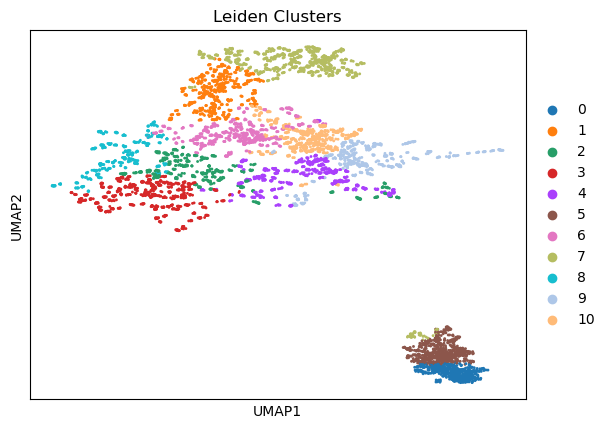

In [17]:
from scipy import sparse

sc.pp.neighbors(adata_RCC, use_rep='embedding', knn=False, method='gauss', key_added='umap')
adata_RCC.obsp['connectivities'] = sparse.csr_matrix(adata_RCC.obsp['connectivities'])
sc.tl.umap(adata_RCC)
sc.pl.umap(adata_RCC, color='leiden', title='Leiden Clusters')

In [18]:
num_regions = adata_RCC.obs['leiden'].nunique()

In [19]:
num_regions

11

In [128]:
from hgctsvg.pipeline import Explainer

pos_gene_idx, neg_gene_idx, pos_attr_norms, neg_attr_norms = Explainer().find_domain_gene_idx("RCC")
# pos_gene_idx, pos_attr_norms = Explainer(project_files_dir).find_domain_gene_idx("RCC", pct=99)

In [129]:
for i, (pidx, nidx) in enumerate(zip(pos_gene_idx, neg_gene_idx)):
    print(i, pidx)
# for i, pidx in enumerate(pos_gene_idx):
#     print(i, pidx, len(pidx))

0 [1057 1139 1131 2543 1082 1080 1165 1126 1178 1489 1267 1094 1079 1173
 1454 1105 1397 1519 1315 1097 1101 1614 1084 1106 1098 1156 1380 1316
 1135 1092 1072 2442 1382 1068 2113 2615 1056 1153 1665 1083 1090 1164
 2778 1066 2821 1218 1820 1058 1856 1186 2344 2622 2085 2192 1343 1149
 1331 1176 1069 2838 2841 1162 2259 1254 1130 1349 2553 2095 2594 1590
 1118 1679 2016 2282 1207 1880 2823 2608 2619 1790 1077 1405 2179 1520
 2435 1293 1651 1067 2194 1258 2000 2590 2125 2329 1166 2276 2348 2630
  334  494 1792 2599 2165 2697 1630 2665 1265 1412 2888 1321 2305 2752
 1081 1942 2606 2397 2175 2321 2980 2328 2919 2193 1493 1550 1971 2505
 1138 1669 2550 1444 2222 2437 1071 2858 2782 2099  831 1771 2452   89
 1583 2864  606 1961 2703 2049 1181 2807  259 2198 2717 1732 1710 2379
 2251 1734 2400 1513 1769 2169 2374 2450  545 1667 2011 1093 2236 2354
 2993 2362 2493 2320 2999 2094 2576 1689 1078 2706 2432 1978 2395 2319
 1944 2231   14 2349 2180 2088 1109 1885 2598 2440 2388 1933 2307 1796
 144

In [130]:
neg_gene_idx

[array([1119, 1088, 2605, 1238, 1073, 1145, 1076, 1154, 1308, 1189, 1341,
        1272, 1941, 1146, 2418, 2660, 1241, 1124, 1065, 1060, 1471, 2643,
        2472, 1208, 1116, 1198, 1621, 1108, 1307, 1831, 1127, 1213, 2725,
        1099, 1413, 1163, 1244, 1564, 1159, 1075, 1151, 1224, 2281, 2010,
        1103, 1225, 1188, 1556, 1095, 1086, 1623, 1063, 1143, 1943, 2795,
        1114, 1147, 1304, 1345, 1144, 1608, 1399, 1451, 2857, 1268, 1155,
        1634, 1408, 2409, 1096, 1352, 2988, 1834, 2624, 2444, 1891, 1363,
        1585, 1152, 1125, 1612, 1133, 2874, 2865, 2079, 1674, 1386, 2246,
        1447, 2300, 2899, 1355, 2740, 2238, 2781, 2291, 2968, 2604, 2802,
        1472, 2567, 1814, 1500, 2268, 2410, 1737, 2257, 2831, 2603,  772,
        2274, 1167, 2803, 2947, 2110, 1641, 2273, 2852, 1384, 2748, 2754,
        1883, 2038, 2667, 1872, 1846, 1438,  517, 1242, 2811, 2461, 2607,
        2491, 2017, 2457,    3, 1973, 2715,  920, 1587, 1809, 1745,   23,
        2733, 2337, 1939, 2895, 1852, 

In [131]:
import pickle
def get_domain_ct_svg_ids(cell_type, feat_idx: dict[int, list]):
    project_metadata = ProjectMetadata()
    
    with open(project_metadata.project_folder / "ct_features.pkl", "rb") as ctff:
        ct_features = pickle.load(ctff)

    gene_ids = ct_features[cell_type]
    ct_svgs = []
    for group_feat_idx in feat_idx:
        ct_svgs.append([gene_ids[idx] for idx in group_feat_idx])

    return ct_svgs   

In [132]:
def filter_ct_svgs(
    adata, groups, var_ids_per_group, group_key='leiden',
    det_thresh=0.8, logfc_thresh=1, eps=1e-9
):
    # --- one-hot (cells × groups)
    G = pd.get_dummies(adata.obs[group_key]).reindex(columns=groups).values  # (n_cells, n_groups)

    # --- union genes (preserve python str)
    all_vars = np.array(
        list(dict.fromkeys(np.concatenate(var_ids_per_group))),
        dtype=object
    )

    # --- expression matrix (cells × genes)
    X = adata[:, all_vars].X
    if hasattr(X, "toarray"):
        X = X.toarray()
    X = X.astype(np.float32)

    # --- detection (same as before)
    X_bin = (X > 0).astype(np.float32)
    n_cells_per_group = G.sum(axis=0)                        # (n_groups,)
    det_counts = G.T @ X_bin                                 # (n_groups × n_genes)
    frac = det_counts / n_cells_per_group[:, None]

    # --- mean expression per group (already in log space)
    sum_expr = G.T @ X
    mean_in = sum_expr / n_cells_per_group[:, None]
    
    # --- out-group mean
    total_sum = X.sum(axis=0, keepdims=True)
    total_n = X.shape[0]
    
    sum_out = total_sum - sum_expr
    n_out = total_n - n_cells_per_group[:, None]
    
    mean_out = sum_out / n_out
    
    # --- logFC (correct for log data)
    logfc = mean_in - mean_out

    # --- mask allowed genes per group
    var_mask = np.zeros((len(groups), len(all_vars)), dtype=bool)
    var_index = {v: i for i, v in enumerate(all_vars)}
    for i, var_list in enumerate(var_ids_per_group):
        var_mask[i, [var_index[v] for v in var_list]] = True

    # --- final filter
    keep = (frac >= det_thresh) & (logfc >= logfc_thresh) & var_mask

    return [
        list(map(str, all_vars[keep[i]]))
        for i in range(len(groups))
    ]

In [133]:
domain_ct_svg_ids = get_domain_ct_svg_ids("RCC", pos_gene_idx)
domain_ct_svg_ids

[['ENSG00000115268',
  'ENSG00000117984',
  'ENSG00000123349',
  'ENSG00000211445',
  'ENSG00000026025',
  'ENSG00000100316',
  'ENSG00000172757',
  'ENSG00000133112',
  'ENSG00000204525',
  'ENSG00000182718',
  'ENSG00000127184',
  'ENSG00000188846',
  'ENSG00000019582',
  'ENSG00000241343',
  'ENSG00000101443',
  'ENSG00000089009',
  'ENSG00000145425',
  'ENSG00000171858',
  'ENSG00000167996',
  'ENSG00000083845',
  'ENSG00000197958',
  'ENSG00000182871',
  'ENSG00000198034',
  'ENSG00000118181',
  'ENSG00000142937',
  'ENSG00000141753',
  'ENSG00000197111',
  'ENSG00000196683',
  'ENSG00000092841',
  'ENSG00000108298',
  'ENSG00000140264',
  'ENSG00000182952',
  'ENSG00000106868',
  'ENSG00000142089',
  'ENSG00000163131',
  'ENSG00000204569',
  'ENSG00000034510',
  'ENSG00000102265',
  'ENSG00000143774',
  'ENSG00000142676',
  'ENSG00000206503',
  'ENSG00000087460',
  'ENSG00000104870',
  'ENSG00000221983',
  'ENSG00000120063',
  'ENSG00000112306',
  'ENSG00000176340',
  'ENSG000001

In [134]:
from functools import reduce

all_pos_genes = reduce(np.union1d, pos_gene_idx)
all_neg_genes = reduce(np.union1d, neg_gene_idx)
all_genes = np.union1d(all_pos_genes, all_neg_genes)
all_genes.shape
# all_genes = reduce(np.union1d, pos_gene_idx)
# all_genes.shape

(1664,)

In [135]:
all_pos_genes.shape, all_neg_genes.shape

((1370,), (1393,))

In [136]:
ct_svg_ids = set()
for ct_svgs in domain_ct_svg_ids:
    ct_svg_ids.update(ct_svgs)
ct_svg_ids = sorted(ct_svg_ids)
len(ct_svg_ids)

1370

In [137]:
domain_ct_svg_ids = filter_ct_svgs(adata_RCC, adata_RCC.obs['leiden'].unique(), domain_ct_svg_ids)

In [138]:
ct_svg_ids = set()
for ct_svgs in domain_ct_svg_ids:
    ct_svg_ids.update(ct_svgs)
ct_svg_ids = sorted(ct_svg_ids)
len(ct_svg_ids)

17

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


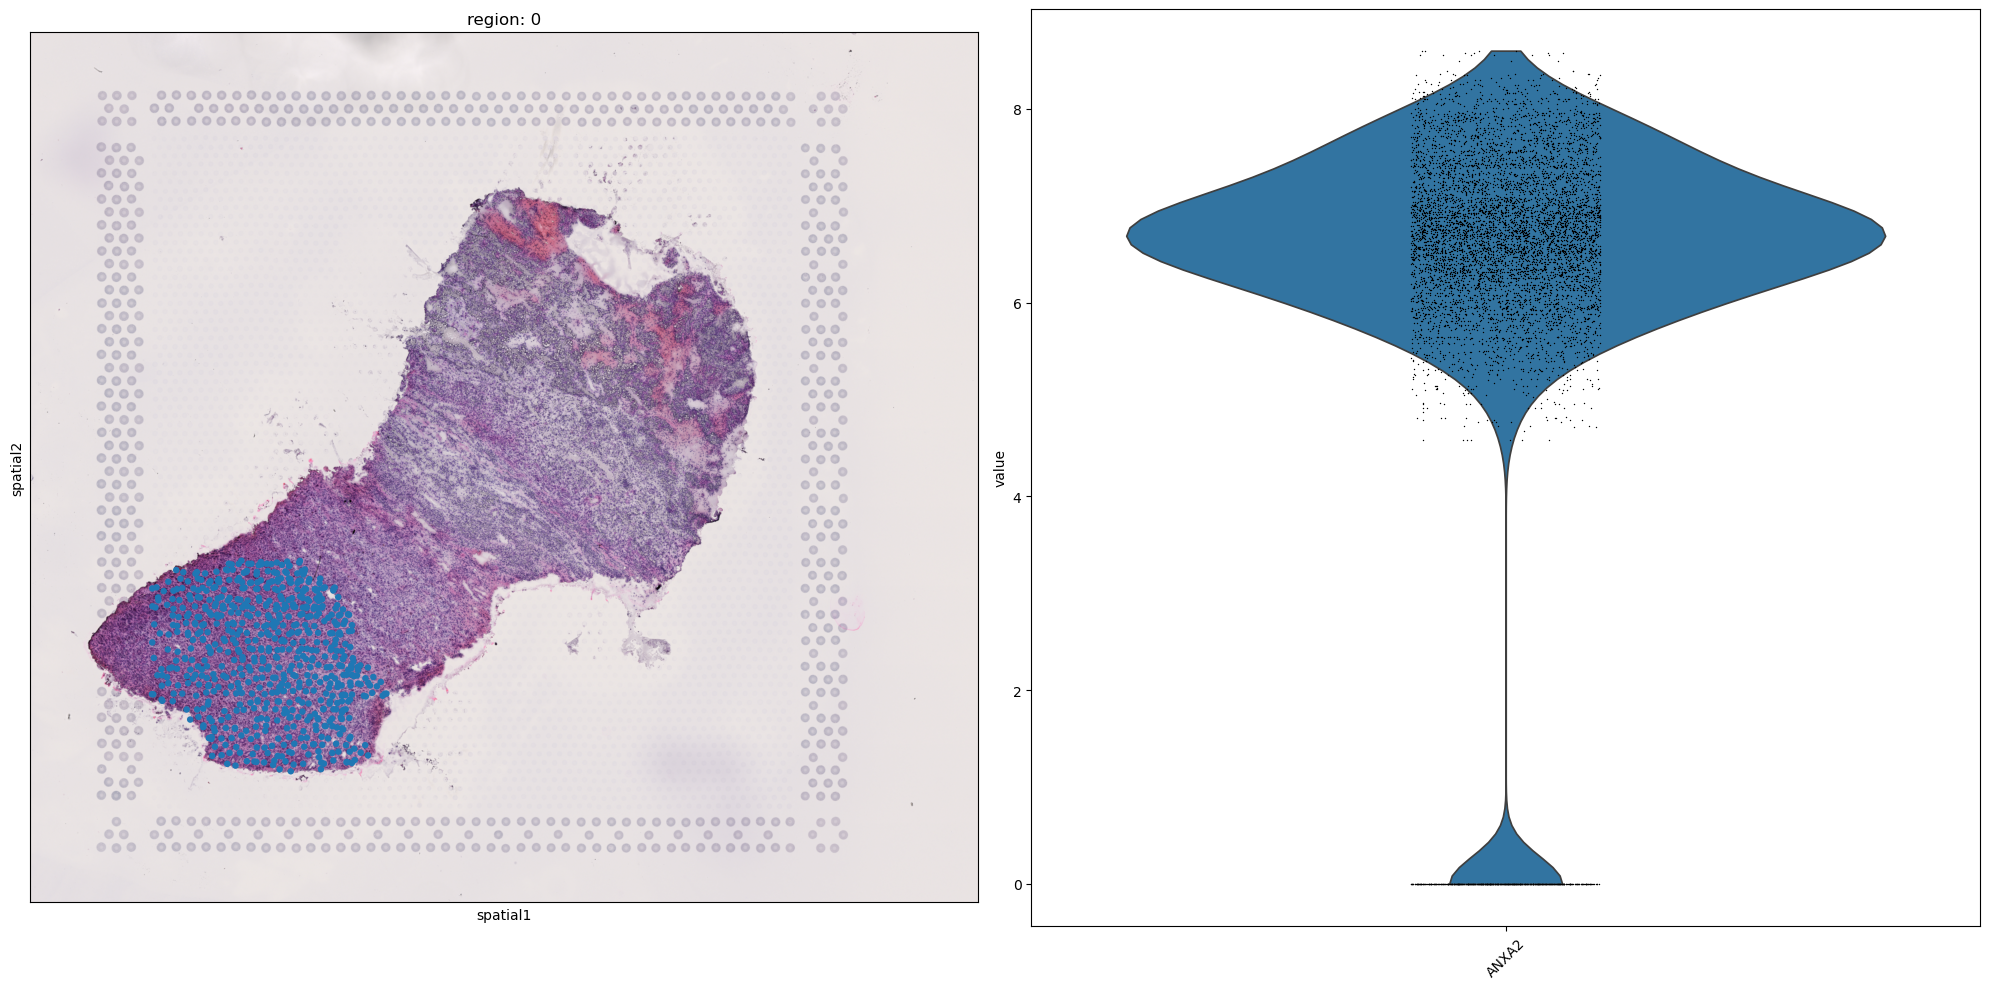

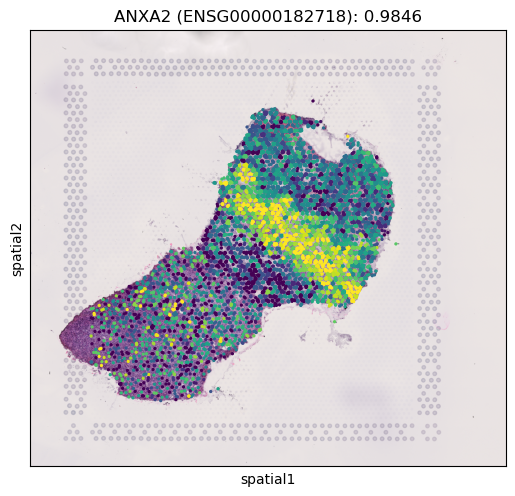

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]


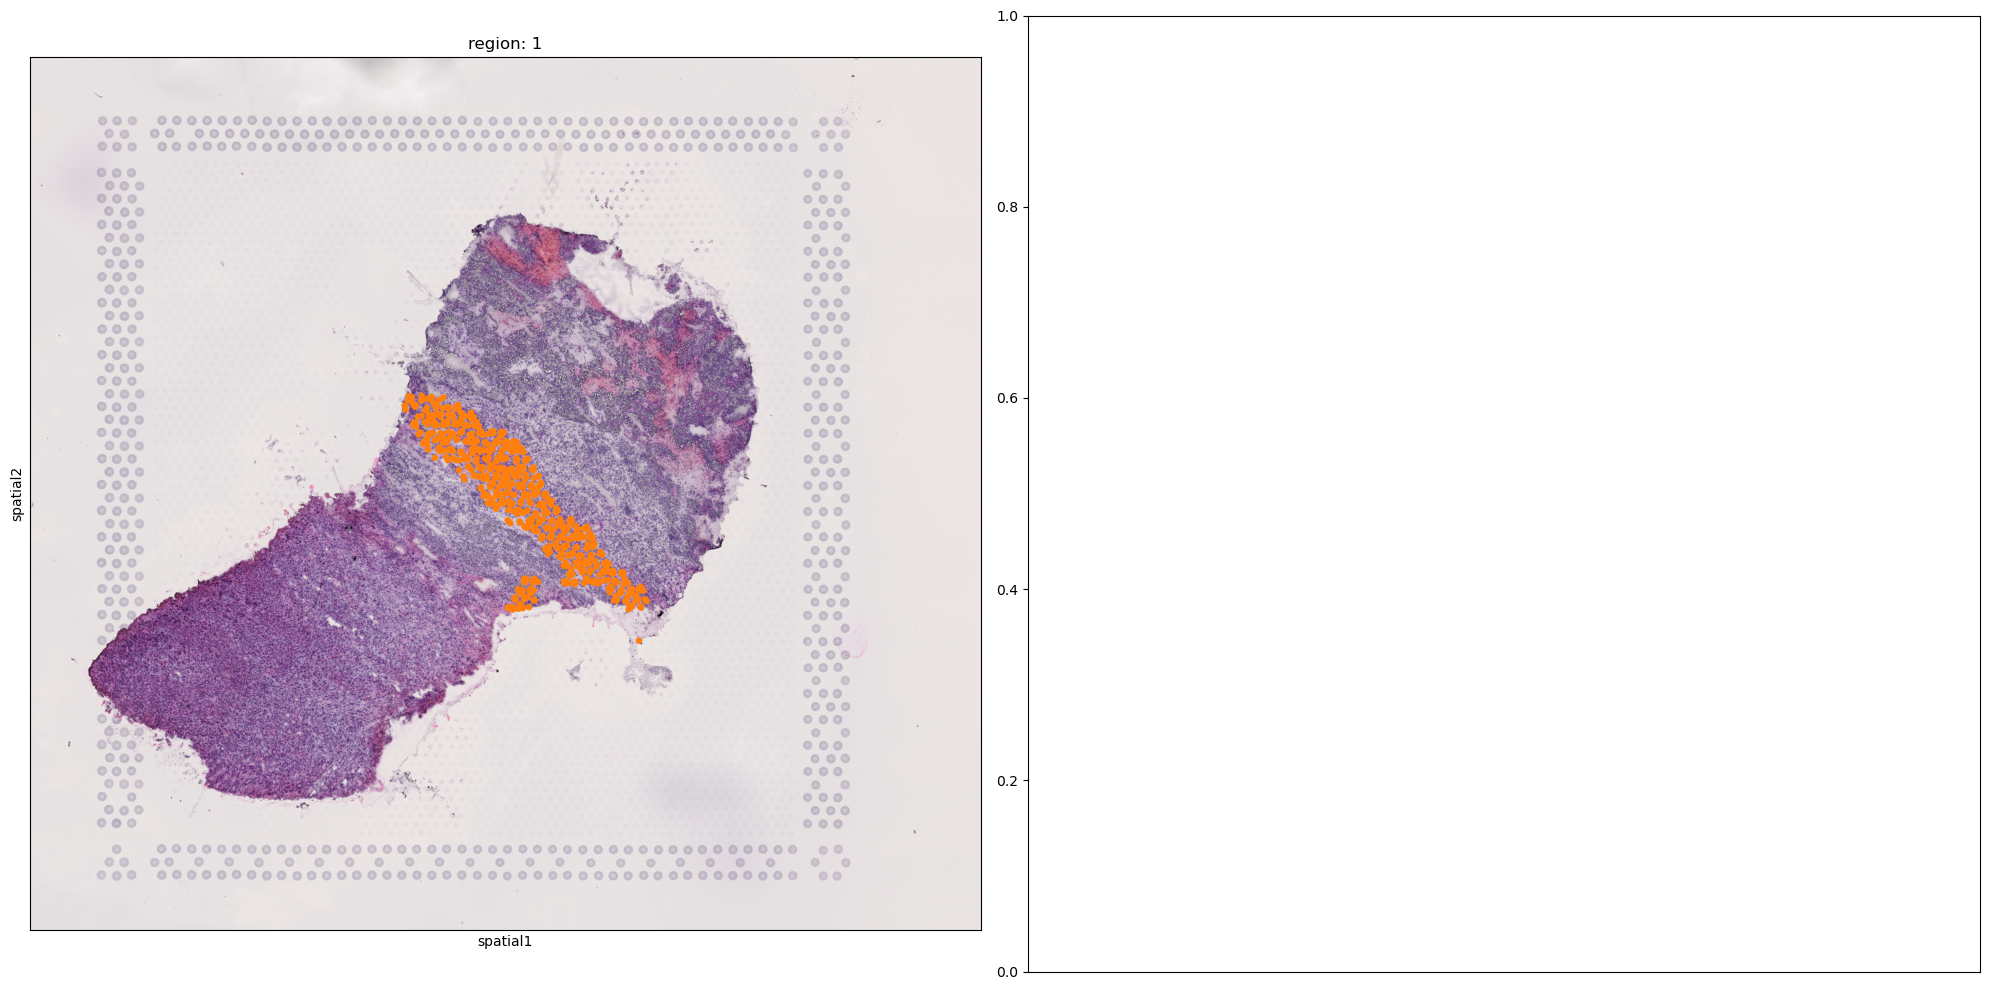

ValueError: Number of rows must be a positive integer, not 0

<Figure size 2000x1500 with 0 Axes>

In [139]:
from hgctsvg.visualization import plot_domain_ct_svgs

for i in range(num_regions):
    plot_domain_ct_svgs(adata_RCC, i, pos_attr_norms[i], domain_ct_svg_ids[i], use_raw=False)

In [ ]:
sc.pp.neighbors(adata_RCC, metric='euclidean', knn=False, method='gauss', key_added='neighbors_PCA')
sc.tl.leiden(adata_RCC, flavor="igraph", neighbors_key='neighbors_PCA', key_added='leiden_PCA', n_iterations=-1, resolution=1)

In [ ]:
sq.pl.spatial_scatter(
    adata_RCC,
    # adata_decomp[adata_decomp.obs['cell_type'] == cell_type],
    color="leiden_PCA", # or a gene name
    # ax=axes[i // n_cols][i % n_cols],
    title="RCC PCA",
    # legend_loc=None
)

In [ ]:
sq.pl.spatial_scatter(
    adata_RCC,
    # adata_decomp[adata_decomp.obs['cell_type'] == cell_type],
    color="leiden", # or a gene name
    # ax=axes[i // n_cols][i % n_cols],
    title="RCC Embedding",
    # legend_loc=None
)